# Video Game Sales: Predicting Global Sales

**Question:** How well can release year, platform, genre, and publisher predict a game's global sales? Which of those characteristics are most useful?

The prediction target is `Global_Sales`, measured in millions of units. I model `log1p(Global_Sales)` because a small number of blockbuster games create a long right tail in sales. Regional sales are explored separately as descriptive data; they are not prediction features because `NA_Sales`, `EU_Sales`, `JP_Sales`, and `Other_Sales` sum to `Global_Sales`. `Rank` is also excluded because it is computed from global sales.

Each row represents a game on a platform. Because the same game can appear on several platforms, all rows with the same game name are kept together when splitting and cross-validating the data.

## Data and preparation

The data are the [Kaggle Video Game Sales dataset](https://www.kaggle.com/datasets/gregorut/videogamesales). It includes games reported to have sold more than 100,000 copies. The code uses `vgsales.csv` in the notebook directory if present; otherwise it downloads a [public Zenodo mirror](https://zenodo.org/records/5898311/files/vgsales.csv?download=1). Sales are recorded in millions of units.

Missing release years and publishers are retained and imputed inside each model pipeline. The game name is used only to form groups, never as a predictor. This avoids using information from a game's other platform entry during evaluation.

Rows after basic cleaning: 16,598
Unique game-name groups: 11,493
Columns: 11 source columns (plus one grouping helper)
Release years: 1980–2020
Missing years: 271; missing publishers: 58
Global sales (millions): median=0.17, mean=0.54, max=82.74


,Name,Platform,Year,Genre,Publisher,Global_Sales
0,Wii Sports,Wii,2006.0,Sports,Nintendo,82.74
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,35.82
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,33.00
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,31.37


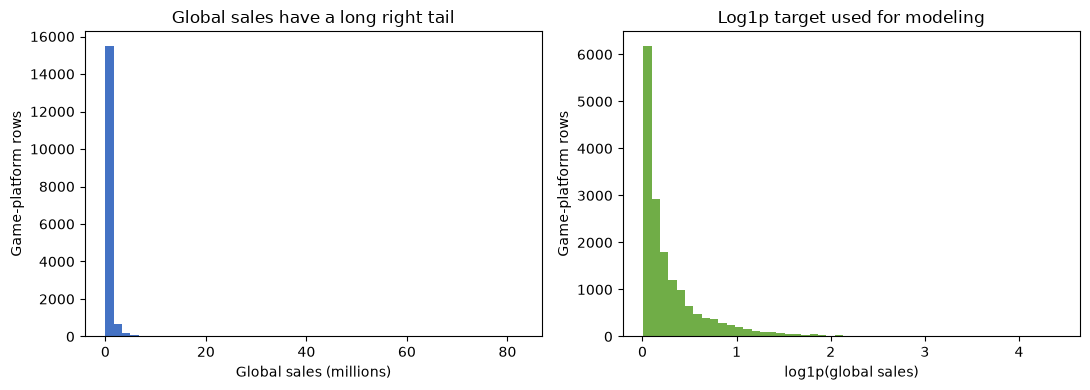

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

data_path = Path("vgsales.csv")
if not data_path.exists():
    url = "https://zenodo.org/records/5898311/files/vgsales.csv?download=1"
    urllib.request.urlretrieve(url, data_path)

games = pd.read_csv(data_path)
expected_columns = {
    "Rank", "Name", "Platform", "Year", "Genre", "Publisher",
    "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"
}
missing_columns = expected_columns.difference(games.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {sorted(missing_columns)}")

# Keep usable target/group rows. Missing predictor values are handled by pipelines below.
games = games.dropna(subset=["Name", "Global_Sales"]).copy()
games["Name"] = games["Name"].astype(str).str.strip()
games = games[(games["Name"] != "") & (games["Global_Sales"] > 0)].copy()
games["Name_Group"] = games["Name"].str.casefold()

print(f"Rows after basic cleaning: {len(games):,}")
print(f"Unique game-name groups: {games['Name_Group'].nunique():,}")
print(f"Columns: {len(games.columns) - 1} source columns (plus one grouping helper)")
print(f"Release years: {games['Year'].min():.0f}–{games['Year'].max():.0f}")
print(f"Missing years: {games['Year'].isna().sum():,}; missing publishers: {games['Publisher'].isna().sum():,}")
print(f"Global sales (millions): median={games['Global_Sales'].median():.2f}, mean={games['Global_Sales'].mean():.2f}, max={games['Global_Sales'].max():.2f}")
display(games[["Name", "Platform", "Year", "Genre", "Publisher", "Global_Sales"]].head())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(games["Global_Sales"], bins=50, color="#4472C4")
axes[0].set(title="Global sales have a long right tail", xlabel="Global sales (millions)", ylabel="Game-platform rows")
axes[1].hist(np.log1p(games["Global_Sales"]), bins=50, color="#70AD47")
axes[1].set(title="Log1p target used for modeling", xlabel="log1p(global sales)", ylabel="Game-platform rows")
fig.tight_layout()
plt.show()

## Methods

TODO

## Results and interpretation

TODO

## Limitations
